# Lucrarea de laborator 1 — CSV/JSON vs Parquet vs Delta Lake

## 1. Configurarea mediului de lucru
`JAVA_HOME` (OpenJDK din env), interpretorul Python pentru Spark și verifică directoarele.

In [2]:
import os
import sys
import subprocess
from pathlib import Path

# ---------- Java (OpenJDK din mediul micromamba) ----------
def find_java_home():
    candidates = []
    if os.environ.get("JAVA_HOME"):
        candidates.append(Path(os.environ["JAVA_HOME"]))
    prefix = Path(sys.prefix)
    candidates += [prefix / "lib" / "jvm", prefix]
    for c in candidates:
        if (c / "bin" / "java").exists():
            return c
    raise FileNotFoundError("Java nu a fost găsit. Instalați: micromamba install -c conda-forge openjdk=17")

JAVA_HOME = find_java_home()
os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["PATH"] = str(JAVA_HOME / "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ.pop("SPARK_HOME", None)   # folosim Spark-ul inclus în pyspark din env

# ---------- Directoare ----------
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PARQUET_DIR = DATA_DIR / "parquet"
PARQUET_PART_DIR = DATA_DIR / "parquet_partitioned"
DELTA_DIR = DATA_DIR / "delta"
for d in [RAW_DIR, PARQUET_DIR, PARQUET_PART_DIR, DELTA_DIR, PROJECT_ROOT / "notebooks"]:
    d.mkdir(parents=True, exist_ok=True)

SOURCE_NAME = "yelp_academic_dataset_review.json"
RAW_FILE = RAW_DIR / SOURCE_NAME
ORIGINAL_FILE = DATA_DIR / SOURCE_NAME          # ../data/yelp_academic_dataset_review.json
if not RAW_FILE.exists():
    if ORIGINAL_FILE.exists():
        RAW_FILE.symlink_to(ORIGINAL_FILE.resolve())   # fără copierea a ~5 GB
        print(f"Creat symlink: {RAW_FILE} -> {ORIGINAL_FILE.resolve()}")
    else:
        raise FileNotFoundError(f"Nu găsesc {SOURCE_NAME} în {DATA_DIR} sau {RAW_DIR}")

assert RAW_FILE.exists()
assert (JAVA_HOME / "bin" / "java").exists()

java_ver = subprocess.run([str(JAVA_HOME / "bin" / "java"), "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("Python      :", sys.version.split()[0], "|", sys.executable)
print("JAVA_HOME   :", JAVA_HOME, "|", java_ver)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("Sursă       :", RAW_FILE, f"({RAW_FILE.stat().st_size / 1024**3:.2f} GB)")

Python      : 3.12.12 | /home/ivan/.mamba/envs/Playground/bin/python
JAVA_HOME   : /home/ivan/.mamba/envs/Playground/lib/jvm | openjdk version "17.0.18-internal" 2026-01-20
PROJECT_ROOT: /home/ivan/tmp/new/big_data/laborator_1
Sursă       : /home/ivan/tmp/new/big_data/laborator_1/data/raw/yelp_academic_dataset_review.json (4.98 GB)


### Crearea sesiunii Spark cu Delta Lake

In [35]:
import pyspark
import delta
from importlib.metadata import version
from pyspark.sql import SparkSession

assert hasattr(delta, "configure_spark_with_delta_pip"), (
    f"Modulul `delta` încărcat din {delta.__file__} nu este delta-spark. Rulați: pip uninstall -y delta")

SPARK_VERSION = pyspark.__version__
SPARK_MM = ".".join(SPARK_VERSION.split(".")[:2])          # ex. 4.1
DELTA_VERSION = version("delta-spark")                      # ex. 4.4.0
DELTA_PACKAGE = f"io.delta:delta-spark_{SPARK_MM}_2.13:{DELTA_VERSION}"

MASTER = "local[*]"        # enunțul folosește local[2]; pe server putem folosi toate nucleele
DRIVER_MEMORY = "8g"

builder = (
    SparkSession.builder
    .master(MASTER)
    .appName("storage-lab")
    .config("spark.driver.memory", DRIVER_MEMORY)
    .config("spark.pyspark.python", sys.executable)
    .config("spark.pyspark.driver.python", sys.executable)
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.jars.packages", DELTA_PACKAGE)
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.ui.showConsoleProgress", "false")
)
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("WARN")

print("Spark :", spark.version, "| master:", spark.sparkContext.master)
print("Delta :", DELTA_PACKAGE)

Spark : 4.1.1 | master: local[*]
Delta : io.delta:delta-spark_4.1_2.13:4.4.0


## 2. Verificări: Python worker și Delta Lake

In [5]:
resultat = (
    spark.sparkContext
    .parallelize([1, 2, 3], 2)
    .map(lambda x: x * 10)
    .collect()
)
assert resultat == [10, 20, 30]
print("PYTHON WORKER: PASS")

test_delta = str(DATA_DIR / "_delta_smoke_test")
spark.range(3).write.format("delta").mode("overwrite").save(test_delta)
assert spark.read.format("delta").load(test_delta).count() == 3
print("DELTA LAKE: PASS")

PYTHON WORKER: PASS


26/09/24 19:11:36 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


DELTA LAKE: PASS


## 3. Încărcarea JSON cu schemă explicită
Fișierul Yelp este **JSON Lines** (un obiect JSON pe linie). Schema este definită explicit (fără `inferSchema`).  
Câmpul `date` are formatul `yyyy-MM-dd HH:mm:ss` și este citit direct ca `TimestampType`. Adăugăm coloana derivată `year`, folosită la filtrare și ca și coloană de partiționare.

In [6]:
from pyspark.sql import functions as F
from pyspark.sql import types as T

review_schema = T.StructType([
    T.StructField("review_id",   T.StringType(),    True),
    T.StructField("user_id",     T.StringType(),    True),
    T.StructField("business_id", T.StringType(),    True),
    T.StructField("stars",       T.DoubleType(),    True),
    T.StructField("useful",      T.LongType(),      True),
    T.StructField("funny",       T.LongType(),      True),
    T.StructField("cool",        T.LongType(),      True),
    T.StructField("text",        T.StringType(),    True),
    T.StructField("date",        T.TimestampType(), True),
])

def read_source():
    return (
        spark.read
        .schema(review_schema)
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .json(str(RAW_DIR))
        .withColumn("year", F.year("date"))
    )

df_src = read_source()
df_src.printSchema()
df_src.show(5, truncate=50)

root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

+----------------------+----------------------+----------------------+-----+------+-----+----+--------------------------------------------------+-------------------+----+
|             review_id|               user_id|           business_id|stars|useful|funny|cool|                                              text|               date|year|
+----------------------+----------------------+----------------------+-----+------+-----+----+--------------------------------------------------+-------------------+----+
|KU_O5udG6zpxOg-VcAEodg|mh_-eMZ6K5RLWhZyISBhwA|XQfwVwDr-v0ZS3_CbbE5Xw|  3.0|     0|    0|   0|If you dec

In [11]:
n_src = df_src.count()
n_bad_dates = df_src.filter(F.col("date").isNull()).count()
print(f"Număr total de rânduri: {n_src:,}")
print(f"Rânduri cu date nulă (verificare format timestamp): {n_bad_dates:,}")

Număr total de rânduri: 6,990,280
Rânduri cu date nulă (verificare format timestamp): 0


### Interogările comune (aceleași pentru toate formatele)
- **Filtrare:** recenziile de 5 stele din anul 2019 → `count()`
- **Agregare:** pentru anii ≥ 2015: numărul de recenzii, media stelelor și media voturilor `useful` pe an → `collect()`

In [7]:
FILTER_YEAR = 2019
AGG_FROM_YEAR = 2015

def q_filter(df):
    return df.filter((F.col("year") == FILTER_YEAR) & (F.col("stars") == 5.0))

def q_agg(df):
    return (
        df.filter(F.col("year") >= AGG_FROM_YEAR)
          .groupBy("year")
          .agg(F.count("*").alias("n_reviews"),
               F.round(F.avg("stars"), 3).alias("avg_stars"),
               F.round(F.avg("useful"), 3).alias("avg_useful"))
          .orderBy("year")
    )

print(f"Filtrare (year={FILTER_YEAR}, stars=5):", f"{q_filter(df_src).count():,}")
q_agg(df_src).show()

Filtrare (year=2019, stars=5): 463,926
+----+---------+---------+----------+
|year|n_reviews|avg_stars|avg_useful|
+----+---------+---------+----------+
|2015|   688415|    3.742|     1.278|
|2016|   758882|    3.766|     1.176|
|2017|   820048|    3.779|     1.035|
|2018|   906362|    3.781|     1.002|
|2019|   907284|    3.767|     0.953|
|2020|   554557|    3.783|       1.0|
|2021|   618189|    3.705|     0.858|
|2022|    31665|    3.705|     0.636|
+----+---------+---------+----------+



### Funcții ajutătoare: dimensiune pe disc și măsurarea timpului

In [8]:
import pandas as pd
from time import perf_counter
from statistics import median

MB = 1024 ** 2
REPEATS = 3
INCLUDE_FULL_SCAN = True   # citire completă a tuturor coloanelor (vezi nota de mai jos)

def dir_size(path):
    """Dimensiunea totală (bytes) a unui fișier/director, recursiv (urmează symlink-urile de fișiere)."""
    path = Path(path)
    if path.is_file():
        return path.stat().st_size
    total = 0
    for root, _, files in os.walk(path):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total

def measure(operation, repeats=REPEATS):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        operation()  # count() sau collect()
        times.append(perf_counter() - start)
    return times, median(times)

SIZES = {}
RESULTS = {}

def benchmark(label, reader, repeats=REPEATS):
    ops = {
        "read_count":   lambda: reader().count(),
        "filter_count": lambda: q_filter(reader()).count(),
        "agg_collect":  lambda: q_agg(reader()).collect(),
    }
    if INCLUDE_FULL_SCAN:
        ops["read_full"] = lambda: reader().write.format("noop").mode("overwrite").save()
    res = {}
    for name, op in ops.items():
        times, med = measure(op, repeats)
        res[name] = {"times": times, "median": med}
        print(f"{label:<20} {name:<13} rulări={[round(t, 2) for t in times]}  mediană={med:.2f} s")
    RESULTS[label] = res
    return res

def results_table():
    rows = []
    for label, res in RESULTS.items():
        row = {"Format": label}
        for op, v in res.items():
            row[f"{op} (s)"] = round(v["median"], 3)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Format")

> **Notă despre „citire”:** `count()` pe Parquet/Delta poate fi rezolvat aproape doar din metadate (footer Parquet / statistici din `_delta_log`), fără a citi coloanele. De aceea am adăugat și `read_full`: scriere în formatul `noop`, care forțează citirea și decodarea **tuturor** coloanelor fără a scrie nimic pe disc. Cerința din enunț (declanșare prin `count()`/`collect()`) este acoperită de `read_count`, `filter_count` și `agg_collect`.

In [9]:
SIZES["JSON (sursă)"] = dir_size(RAW_DIR)
print(f"Dimensiune sursă: {SIZES['JSON (sursă)'] / MB:,.1f} MB")
benchmark("JSON (sursă)", read_source);

Dimensiune sursă: 5,094.4 MB
JSON (sursă)         read_count    rulări=[3.39, 3.34, 3.42]  mediană=3.39 s
JSON (sursă)         filter_count  rulări=[3.55, 3.62, 3.57]  mediană=3.57 s
JSON (sursă)         agg_collect   rulări=[6.22, 6.08, 5.99]  mediană=6.08 s
JSON (sursă)         read_full     rulări=[7.71, 7.41, 7.37]  mediană=7.41 s


## 4. Salvarea și recitirea datelor în Parquet

In [12]:
t0 = perf_counter()
df_src.write.mode("overwrite").parquet(str(PARQUET_DIR))
print(f"Scriere Parquet: {perf_counter() - t0:.1f} s")

def read_parquet():
    return spark.read.parquet(str(PARQUET_DIR))

df_pq = read_parquet()
df_pq.printSchema()

def schema_signature(df):
    return [(f.name, f.dataType.simpleString()) for f in df.schema.fields]

n_pq = df_pq.count()
assert n_pq == n_src, (n_pq, n_src)
assert schema_signature(df_pq) == schema_signature(df_src)
print(f"Rânduri Parquet = {n_pq:,} (identic cu sursa), schema corespunde: OK")

Scriere Parquet: 15.0 s
root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

Rânduri Parquet = 6,990,280 (identic cu sursa), schema corespunde: OK


## 5. Compararea dimensiunilor și a timpului: sursă vs Parquet

In [13]:
SIZES["Parquet"] = dir_size(PARQUET_DIR)
src_mb, pq_mb = SIZES["JSON (sursă)"] / MB, SIZES["Parquet"] / MB
diff_mb = pq_mb - src_mb
pct = diff_mb / src_mb * 100
n_files = len(list(PARQUET_DIR.glob("*.parquet")))

print(f"Sursă JSON : {src_mb:,.1f} MB")
print(f"Parquet    : {pq_mb:,.1f} MB  ({n_files} fișiere .parquet, compresie snappy)")
print(f"Diferență  : {diff_mb:+,.1f} MB  ->  Parquet ocupă {abs(pct):.1f}% "
      f"{'mai puțin' if pct < 0 else 'mai mult'} decât sursa")

Sursă JSON : 5,094.4 MB
Parquet    : 2,876.1 MB  (40 fișiere .parquet, compresie snappy)
Diferență  : -2,218.3 MB  ->  Parquet ocupă 43.5% mai puțin decât sursa


In [14]:
benchmark("Parquet", read_parquet)
results_table()

Parquet              read_count    rulări=[0.14, 0.13, 0.13]  mediană=0.13 s
Parquet              filter_count  rulări=[0.97, 0.2, 0.18]  mediană=0.20 s
Parquet              agg_collect   rulări=[0.67, 0.37, 0.44]  mediană=0.44 s
Parquet              read_full     rulări=[4.63, 4.06, 4.02]  mediană=4.06 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),3.391,3.571,6.083,7.413
Parquet,0.132,0.201,0.441,4.058


## 6. Parquet partiționat
Coloana de partiționare: **`year`** (~18 valori distincte, 2005–2022) — nu este identificator unic, iar interogările noastre filtrează după ea.  
`repartition("year")` înainte de scriere produce un singur fișier per partiție (evită multe fișiere mici).

In [15]:
t0 = perf_counter()
(df_src.repartition("year")
       .write.mode("overwrite")
       .partitionBy("year")
       .parquet(str(PARQUET_PART_DIR)))
print(f"Scriere Parquet partiționat: {perf_counter() - t0:.1f} s")

def read_parquet_part():
    return spark.read.parquet(str(PARQUET_PART_DIR))

df_pq_part = read_parquet_part()
assert df_pq_part.count() == n_src
assert schema_signature(df_pq_part) == schema_signature(df_src)
SIZES["Parquet partiționat"] = dir_size(PARQUET_PART_DIR)
print(f"Dimensiune: {SIZES['Parquet partiționat'] / MB:,.1f} MB")

Scriere Parquet partiționat: 23.3 s
Dimensiune: 2,870.1 MB


In [16]:
benchmark("Parquet partiționat", read_parquet_part)
results_table()

Parquet partiționat  read_count    rulări=[0.11, 0.1, 0.1]  mediană=0.10 s
Parquet partiționat  filter_count  rulări=[0.15, 0.1, 0.09]  mediană=0.10 s
Parquet partiționat  agg_collect   rulări=[0.45, 0.24, 0.23]  mediană=0.24 s
Parquet partiționat  read_full     rulări=[4.07, 3.85, 3.86]  mediană=3.86 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),3.391,3.571,6.083,7.413
Parquet,0.132,0.201,0.441,4.058
Parquet partiționat,0.104,0.096,0.244,3.864


## 7. Verificarea partițiilor și `PartitionFilters`
Fiecare valoare distinctă a coloanei `year` devine un director `year=<valoare>`. Valoarea **nu mai este stocată în fișierele Parquet** — Spark o reconstruiește din numele directorului (partition discovery).

In [17]:
part_rows = []
for d in sorted(PARQUET_PART_DIR.glob("year=*")):
    files = list(d.glob("*.parquet"))
    part_rows.append({"director": d.name,
                      "year": int(d.name.split("=")[1]),
                      "fișiere .parquet": len(files),
                      "MB": round(dir_size(d) / MB, 1)})
df_parts = pd.DataFrame(part_rows).set_index("year")

counts = {r["year"]: r["count"] for r in df_pq_part.groupBy("year").count().collect()}
df_parts["rânduri"] = df_parts.index.map(counts)
df_parts

,director,fișiere .parquet,MB,rânduri
year,,,,
2005,year=2005,1,0.3,854
2006,year=2006,1,1.6,3853
2007,year=2007,1,7.2,15363
2008,year=2008,1,25.5,48226
2009,year=2009,1,38.8,74387
2010,year=2010,1,70.4,138587
2011,year=2011,1,115.4,230813
2012,year=2012,1,139.7,286570
2013,year=2013,1,179.5,383950


In [18]:
# legătura rând -> fișier: calea fișierului conține valoarea partiției
(df_pq_part.filter(F.col("year").isin(2010, 2019))
    .select("review_id", "year", F.col("_metadata.file_path").alias("file_path"))
    .dropDuplicates(["year"])
    .show(truncate=False))

# un fișier dintr-o partiție, citit direct: NU conține coloana year
one_file = next((PARQUET_PART_DIR / f"year={FILTER_YEAR}").glob("*.parquet"))
print("Coloane în fișierul fizic:", spark.read.parquet(str(one_file)).columns)

+----------------------+----+---------------------------------------------------------------------------------------------------------------------------------------------------+
|review_id             |year|file_path                                                                                                                                          |
+----------------------+----+---------------------------------------------------------------------------------------------------------------------------------------------------+
|jazQvYxoflZm6BBjmh1gZg|2010|file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned/year=2010/part-00011-367f4f25-4f5c-4a56-9495-4127754b86b5.c000.snappy.parquet|
|F6VdYuJiefNBfn3HNELv0A|2019|file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned/year=2019/part-00006-367f4f25-4f5c-4a56-9495-4127754b86b5.c000.snappy.parquet|
+----------------------+----+---------------------------------------------------------------------------------

In [19]:
import io
import contextlib

def explain_str(df, mode="formatted"):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode)
    return buf.getvalue()

def show_scan_info(title, df):
    plan = explain_str(q_filter(df))
    print("=" * 100)
    print(title)
    print("=" * 100)
    print(plan)
    print("--- extras din nodul Scan ---")
    for line in plan.splitlines():
        if any(k in line for k in ("PartitionFilters", "PushedFilters", "ReadSchema")):
            print("   ", line.strip())
    return plan

plan_pq = show_scan_info("Parquet NEpartiționat", read_parquet())

Parquet NEpartiționat
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#1971, user_id#1972, business_id#1973, stars#1974, useful#1975L, funny#1976L, cool#1977L, text#1978, date#1979, year#1980]
Batched: true
Location: InMemoryFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet]
PushedFilters: [IsNotNull(year), IsNotNull(stars), EqualTo(year,2019), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp,year:int>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#1971, user_id#1972, business_id#1973, stars#1974, useful#1975L, funny#1976L, cool#1977L, text#1978, date#1979, year#1980]

(3) Filter [codegen id : 1]
Input [10]: [review_id#1971, user_id#1972, business_id#1973, stars#1974, useful#1975L, funny#1976L, cool#1977L, text#1978, date#1979, year#1980]
Condition : (((isnotnull(

In [20]:
plan_pq_part = show_scan_info("Parquet PARTIȚIONAT", read_parquet_part())
assert "PartitionFilters: [" in plan_pq_part and "year" in plan_pq_part.split("PartitionFilters:")[1].split("\n")[0]
print("\nPartitionFilters conține condiția pe `year` -> partition pruning activ.")

Parquet PARTIȚIONAT
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#1982, user_id#1983, business_id#1984, stars#1985, useful#1986L, funny#1987L, cool#1988L, text#1989, date#1990, year#1991]
Batched: true
Location: InMemoryFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned]
PartitionFilters: [isnotnull(year#1991), (year#1991 = 2019)]
PushedFilters: [IsNotNull(stars), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#1982, user_id#1983, business_id#1984, stars#1985, useful#1986L, funny#1987L, cool#1988L, text#1989, date#1990, year#1991]

(3) Filter [codegen id : 1]
Input [10]: [review_id#1982, user_id#1983, business_id#1984, stars#1985, useful#1986L, funny#1987L, cool#1988L, text#1989, date#1990, year#1991]


**Interpretare:**
- La Parquet **nepartiționat**, condiția `year = 2019` apare doar în `PushedFilters` / `Filter`: Spark deschide toate fișierele și folosește statisticile min/max din row groups pentru a sări peste o parte din date.
- La Parquet **partiționat**, condiția apare în `PartitionFilters`: Spark elimină directoarele `year≠2019` încă din faza de planificare (partition pruning) și citește doar `year=2019/`. `PushedFilters` rămâne doar pentru `stars = 5.0`.

## 8. Tabel Delta partiționat
Directorul Delta se șterge înainte de scriere, pentru ca **versiunea 0** să fie exact încărcarea inițială (la rulări repetate, `overwrite` ar crea o versiune nouă, nu v0).

In [21]:
import shutil
shutil.rmtree(DELTA_DIR, ignore_errors=True)

t0 = perf_counter()
(df_src.repartition("year")
       .write.format("delta")
       .mode("overwrite")
       .partitionBy("year")
       .save(str(DELTA_DIR)))
print(f"Scriere Delta: {perf_counter() - t0:.1f} s")

def read_delta():
    return spark.read.format("delta").load(str(DELTA_DIR))

df_delta = read_delta()
df_delta.printSchema()
n_delta_v0 = df_delta.count()
assert n_delta_v0 == n_src
assert schema_signature(df_delta) == schema_signature(df_src)
SIZES["Delta Lake"] = dir_size(DELTA_DIR)
print(f"Rânduri Delta = {n_delta_v0:,}, schema OK, dimensiune = {SIZES['Delta Lake'] / MB:,.1f} MB")

Scriere Delta: 27.0 s
root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

Rânduri Delta = 6,990,280, schema OK, dimensiune = 2,870.2 MB


In [22]:
benchmark("Delta Lake", read_delta)
results_table()

Delta Lake           read_count    rulări=[0.14, 0.13, 0.16]  mediană=0.14 s
Delta Lake           filter_count  rulări=[0.41, 0.24, 0.26]  mediană=0.26 s
Delta Lake           agg_collect   rulări=[1.36, 0.61, 0.51]  mediană=0.61 s
Delta Lake           read_full     rulări=[4.27, 4.18, 4.07]  mediană=4.18 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),3.391,3.571,6.083,7.413
Parquet,0.132,0.201,0.441,4.058
Parquet partiționat,0.104,0.096,0.244,3.864
Delta Lake,0.144,0.257,0.611,4.176


In [23]:
plan_delta = show_scan_info("Delta Lake (partiționat)", read_delta())

Delta Lake (partiționat)
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#4951, user_id#4952, business_id#4953, stars#4954, useful#4955L, funny#4956L, cool#4957L, text#4958, date#4959, year#4960]
Batched: true
Location: PreparedDeltaFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/delta]
PartitionFilters: [isnotnull(year#4960), (year#4960 = 2019)]
PushedFilters: [IsNotNull(stars), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#4951, user_id#4952, business_id#4953, stars#4954, useful#4955L, funny#4956L, cool#4957L, text#4958, date#4959, year#4960]

(3) Filter [codegen id : 1]
Input [10]: [review_id#4951, user_id#4952, business_id#4953, stars#4954, useful#4955L, funny#4956L, cool#4957L, text#4958, date#4959, year#4960]
Cond

## 9. Inspectarea fișierelor Delta

In [24]:
import json
from collections import Counter

LOG_DIR = DELTA_DIR / "_delta_log"
data_files = [p for p in DELTA_DIR.rglob("*.parquet") if "_delta_log" not in p.parts]

print("Conținut director Delta:")
for p in sorted(DELTA_DIR.iterdir())[:6]:
    print("  ", p.name + ("/" if p.is_dir() else ""))
print("   ...")
print(f"Directoare de partiții : {len(list(DELTA_DIR.glob('year=*')))}")
print(f"Fișiere de date Parquet: {len(data_files)}  ({sum(f.stat().st_size for f in data_files) / MB:,.1f} MB)")
print(f"Exemplu fișier de date : {data_files[0].relative_to(DELTA_DIR)}")
print("\n_delta_log:")
for p in sorted(LOG_DIR.iterdir()):
    print(f"   {p.name:<45} {p.stat().st_size:>10,} B")

Conținut director Delta:
   _delta_log/
   year=2005/
   year=2006/
   year=2007/
   year=2008/
   year=2009/
   ...
Directoare de partiții : 18
Fișiere de date Parquet: 18  (2,847.9 MB)
Exemplu fișier de date : year=2018/part-00001-cbc08c0d-c169-4ecf-848f-2eb76fff90df.c000.snappy.parquet

_delta_log:
   .00000000000000000000.crc.crc                        164 B
   .00000000000000000000.json.crc                       156 B
   00000000000000000000.crc                          19,591 B
   00000000000000000000.json                         18,465 B
   _staged_commits                                    4,096 B


In [25]:
with open(LOG_DIR / "00000000000000000000.json") as f:
    actions = [json.loads(line) for line in f]

print("Acțiuni în commit-ul 0:", dict(Counter(next(iter(a)) for a in actions)))
commit = next(a["commitInfo"] for a in actions if "commitInfo" in a)
print("Operație:", commit["operation"], "|", commit.get("operationParameters"))
meta = next(a["metaData"] for a in actions if "metaData" in a)
print("Coloane de partiționare:", meta["partitionColumns"])

first_add = next(a["add"] for a in actions if "add" in a)
print("\nExemplu acțiune `add`:")
print("  path           :", first_add["path"])
print("  partitionValues:", first_add["partitionValues"])
print("  size           :", f"{first_add['size']:,} B")
print("  stats          :", first_add["stats"][:250], "...")

# fișierele de date Delta sunt fișiere Parquet obișnuite
print("\nCitit direct ca Parquet:", spark.read.parquet(str(data_files[0])).count(), "rânduri")

Acțiuni în commit-ul 0: {'commitInfo': 1, 'metaData': 1, 'protocol': 1, 'add': 18}
Operație: WRITE | {'mode': 'Overwrite', 'partitionBy': '["year"]'}
Coloane de partiționare: ['year']

Exemplu acțiune `add`:
  path           : year=2007/part-00000-a51892d4-04a1-4d4a-b798-fced83e7c12c.c000.snappy.parquet
  partitionValues: {'year': '2007'}
  size           : 7,504,852 B
  stats          : {"numRecords":15363,"minValues":{"review_id":"--7P9vyDUYRTlGN5jBjivw","user_id":"--FtJYX8N228l3HPB7hkKQ","business_id":"--O3ip9NpXTKD4oBS1pY2A","stars":1.0,"useful":0,"funny":0,"cool":0,"text":"\" I like sushi cuz it's so delic","date":"2007-01-01T02 ...

Citit direct ca Parquet: 906362 rânduri


**Concluzie:** datele tabelului Delta sunt fișiere Parquet obișnuite (organizate în directoare `year=...`), iar `_delta_log/` conține commit-uri JSON numerotate (`00000000000000000000.json`, ...). Fiecare commit descrie acțiunile tranzacției (`add`/`remove` fișiere, `metaData`, `protocol`, `commitInfo`); starea tabelului la o versiune = rejucarea log-ului până la acea versiune.

## 10. Crearea versiunilor Delta
| Versiune | Operație | Ce facem |
|---|---|---|
| v0 | WRITE (overwrite) | încărcarea inițială |
| v1 | WRITE (append) | adăugăm 5 recenzii noi, anul 2023 (partiție nouă) |
| v2 | UPDATE | 5 recenzii reale din 2012: `stars = 1.0`, `useful += 1000` |
| v3 | DELETE | ștergem toate recenziile din cel mai vechi an |

In [26]:
from datetime import datetime
from delta.tables import DeltaTable

dt = DeltaTable.forPath(spark, str(DELTA_DIR))

# ---------- v1: APPEND ----------
append_rows = [
    (f"LAB01_APPEND_{i:03d}", "LAB01_USER", "LAB01_BUSINESS", 4.0, 0, 0, 0,
     f"Recenzie adăugată în laborator #{i}", datetime(2023, 1, i, 12, 0, 0), 2023)
    for i in range(1, 6)
]
append_ids = [r[0] for r in append_rows]
df_append = spark.createDataFrame(append_rows, schema=read_delta().schema)
df_append.write.format("delta").mode("append").save(str(DELTA_DIR))

read_delta().filter(F.col("review_id").isin(append_ids)).select("review_id", "stars", "date", "year").show()
print("Partiție nouă creată:", (DELTA_DIR / "year=2023").exists())

+----------------+-----+-------------------+----+
|       review_id|stars|               date|year|
+----------------+-----+-------------------+----+
|LAB01_APPEND_001|  4.0|2023-01-01 10:00:00|2023|
|LAB01_APPEND_004|  4.0|2023-01-04 10:00:00|2023|
|LAB01_APPEND_003|  4.0|2023-01-03 10:00:00|2023|
|LAB01_APPEND_002|  4.0|2023-01-02 10:00:00|2023|
|LAB01_APPEND_005|  4.0|2023-01-05 10:00:00|2023|
+----------------+-----+-------------------+----+

Partiție nouă creată: True


In [27]:
# ---------- v2: UPDATE ----------
UPDATE_YEAR = 2012
update_ids = [r.review_id for r in (
    read_delta().filter((F.col("year") == UPDATE_YEAR) & (F.col("stars") != 1.0))
                .select("review_id").orderBy("review_id").limit(5).collect())]

print("Înainte de UPDATE:")
read_delta().filter(F.col("review_id").isin(update_ids)).select("review_id", "stars", "useful", "year").show()

dt.update(
    condition=(F.col("year") == UPDATE_YEAR) & F.col("review_id").isin(update_ids),
    set={"stars": F.lit(1.0), "useful": F.col("useful") + 1000},
)

print("După UPDATE:")
read_delta().filter(F.col("review_id").isin(update_ids)).select("review_id", "stars", "useful", "year").show()

Înainte de UPDATE:
+--------------------+-----+------+----+
|           review_id|stars|useful|year|
+--------------------+-----+------+----+
|--2aapBd7imcn5Kug...|  4.0|     0|2012|
|---hY_aTcGUhJT688...|  5.0|     1|2012|
|--3AB1jU10He29Cvh...|  4.0|     1|2012|
|---v3SgPiNYCHZa2f...|  4.0|     1|2012|
|--0abhSo7d0AdREbs...|  4.0|     0|2012|
+--------------------+-----+------+----+



26/09/24 19:23:33 WARN UpdateCommand: Could not validate number of records due to missing statistics.


După UPDATE:
+--------------------+-----+------+----+
|           review_id|stars|useful|year|
+--------------------+-----+------+----+
|--2aapBd7imcn5Kug...|  1.0|  1000|2012|
|---hY_aTcGUhJT688...|  1.0|  1001|2012|
|--3AB1jU10He29Cvh...|  1.0|  1001|2012|
|---v3SgPiNYCHZa2f...|  1.0|  1001|2012|
|--0abhSo7d0AdREbs...|  1.0|  1000|2012|
+--------------------+-----+------+----+



In [28]:
# ---------- v3: DELETE ----------
DELETE_YEAR = int(df_parts.index.min())        # cel mai vechi an din date
n_deleted = read_delta().filter(F.col("year") == DELETE_YEAR).count()
print(f"Rânduri din {DELETE_YEAR} înainte de DELETE: {n_deleted:,}")

dt.delete(F.col("year") == DELETE_YEAR)

print(f"Rânduri din {DELETE_YEAR} după DELETE   : {read_delta().filter(F.col('year') == DELETE_YEAR).count():,}")
print(f"Directorul year={DELETE_YEAR} încă există pe disc (necesar pentru time travel): "
      f"{(DELTA_DIR / f'year={DELETE_YEAR}').exists()}")

Rânduri din 2005 înainte de DELETE: 854
Rânduri din 2005 după DELETE   : 0
Directorul year=2005 încă există pe disc (necesar pentru time travel): True


## 11. Istoricul și citirea versiunii 0 (time travel)

In [29]:
history = (dt.history()
             .select("version", "timestamp", "operation", "operationParameters", "operationMetrics")
             .orderBy("version"))
hist_pd = history.toPandas()
display(hist_pd[["version", "timestamp", "operation", "operationParameters"]])

print("Fișiere în _delta_log:", sorted(p.name for p in LOG_DIR.glob("*.json")))
assert list(hist_pd["operation"]) == ["WRITE", "WRITE", "UPDATE", "DELETE"], list(hist_pd["operation"])

,version,timestamp,operation,operationParameters
0,0,2026-09-24 16:21:16.342,WRITE,"{'mode': 'Overwrite', 'partitionBy': '[""year""]'}"
1,1,2026-09-24 16:23:03.914,WRITE,"{'mode': 'Append', 'partitionBy': '[]'}"
2,2,2026-09-24 16:23:33.495,UPDATE,"{'predicate': '[""((year#5067 = 2012) AND revie..."
3,3,2026-09-24 16:23:45.837,DELETE,"{'predicate': '[""(year#5067 = 2005)""]'}"


Fișiere în _delta_log: ['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json', '00000000000000000003.json']


In [30]:
v0 = spark.read.format("delta").option("versionAsOf", 0).load(str(DELTA_DIR))
cur = read_delta()

n_v0, n_cur = v0.count(), cur.count()
expected = n_v0 + len(append_ids) - n_deleted
print(f"v0      : {n_v0:,} rânduri")
print(f"curent  : {n_cur:,} rânduri  (= v0 + {len(append_ids)} append - {n_deleted:,} delete = {expected:,})")
assert n_cur == expected

print("\nNumăr de rânduri pe fiecare versiune:")
for v in hist_pd["version"]:
    print(f"  v{v}: {spark.read.format('delta').option('versionAsOf', int(v)).load(str(DELTA_DIR)).count():,}")

v0      : 6,990,280 rânduri
curent  : 6,989,431 rânduri  (= v0 + 5 append - 854 delete = 6,989,431)

Număr de rânduri pe fiecare versiune:
  v0: 6,990,280
  v1: 6,990,285
  v2: 6,990,285
  v3: 6,989,431


In [31]:
cols = ["versiune", "review_id", "stars", "useful", "year"]
affected = update_ids + append_ids
cmp = (v0.withColumn("versiune", F.lit("v0")).filter(F.col("review_id").isin(affected)).select(cols)
       .unionByName(cur.withColumn("versiune", F.lit("curent")).filter(F.col("review_id").isin(affected)).select(cols))
       .orderBy("review_id", F.desc("versiune")))
print("Înregistrări modificate (UPDATE) și adăugate (APPEND): v0 vs curent")
cmp.show(30, truncate=False)

print(f"Rânduri din anul {DELETE_YEAR}: v0 = {v0.filter(F.col('year') == DELETE_YEAR).count():,} | "
      f"curent = {cur.filter(F.col('year') == DELETE_YEAR).count():,}")
SIZES["Delta Lake (după v3)"] = dir_size(DELTA_DIR)

Înregistrări modificate (UPDATE) și adăugate (APPEND): v0 vs curent
+--------+----------------------+-----+------+----+
|versiune|review_id             |stars|useful|year|
+--------+----------------------+-----+------+----+
|v0      |---hY_aTcGUhJT688aZO3w|5.0  |1     |2012|
|curent  |---hY_aTcGUhJT688aZO3w|1.0  |1001  |2012|
|v0      |---v3SgPiNYCHZa2f64OHA|4.0  |1     |2012|
|curent  |---v3SgPiNYCHZa2f64OHA|1.0  |1001  |2012|
|v0      |--0abhSo7d0AdREbsFStPw|4.0  |0     |2012|
|curent  |--0abhSo7d0AdREbsFStPw|1.0  |1000  |2012|
|v0      |--2aapBd7imcn5Kug4YY0Q|4.0  |0     |2012|
|curent  |--2aapBd7imcn5Kug4YY0Q|1.0  |1000  |2012|
|v0      |--3AB1jU10He29Cvh9Xsfg|4.0  |1     |2012|
|curent  |--3AB1jU10He29Cvh9Xsfg|1.0  |1001  |2012|
|curent  |LAB01_APPEND_001      |4.0  |0     |2023|
|curent  |LAB01_APPEND_002      |4.0  |0     |2023|
|curent  |LAB01_APPEND_003      |4.0  |0     |2023|
|curent  |LAB01_APPEND_004      |4.0  |0     |2023|
|curent  |LAB01_APPEND_005      |4.0  |0     |20

## 12. Concluzia — comparație pe baza valorilor măsurate

In [32]:
features = {
    "JSON (sursă)":        ("Nu (fișier unic)",        "Nu"),
    "Parquet":             ("Nu (posibil, nefolosit)", "Nu"),
    "Parquet partiționat": ("Da (year=...)",           "Nu"),
    "Delta Lake":          ("Da (year=...)",           "Da (versionAsOf)"),
}
src_size = SIZES["JSON (sursă)"]
rows = []
for label in ["JSON (sursă)", "Parquet", "Parquet partiționat", "Delta Lake"]:
    r = RESULTS[label]
    row = {
        "Format": label,
        "Dimensiune (MB)": round(SIZES[label] / MB, 1),
        "vs sursă (%)": round((SIZES[label] - src_size) / src_size * 100, 1),
        "Citire count() mediană (s)": round(r["read_count"]["median"], 2),
    }
    if "read_full" in r:
        row["Citire completă mediană (s)"] = round(r["read_full"]["median"], 2)
    row["Filtrare mediană (s)"] = round(r["filter_count"]["median"], 2)
    row["Agregare mediană (s)"] = round(r["agg_collect"]["median"], 2)
    row["Partiționare"], row["Istoric versiuni"] = features[label]
    rows.append(row)

summary = pd.DataFrame(rows).set_index("Format")
print(f"Delta Lake după v3 (inclusiv fișiere vechi păstrate pentru time travel): "
      f"{SIZES['Delta Lake (după v3)'] / MB:,.1f} MB")
summary

Delta Lake după v3 (inclusiv fișiere vechi păstrate pentru time travel): 3,009.9 MB


,Dimensiune (MB),vs sursă (%),Citire count() mediană (s),Citire completă mediană (s),Filtrare mediană (s),Agregare mediană (s),Partiționare,Istoric versiuni
Format,,,,,,,,
JSON (sursă),5094.4,0.0,3.39,7.41,3.57,6.08,Nu (fișier unic),Nu
Parquet,2876.1,-43.5,0.13,4.06,0.20,0.44,"Nu (posibil, nefolosit)",Nu
Parquet partiționat,2870.1,-43.7,0.10,3.86,0.10,0.24,Da (year=...),Nu
Delta Lake,2870.2,-43.7,0.14,4.18,0.26,0.61,Da (year=...),Da (versionAsOf)


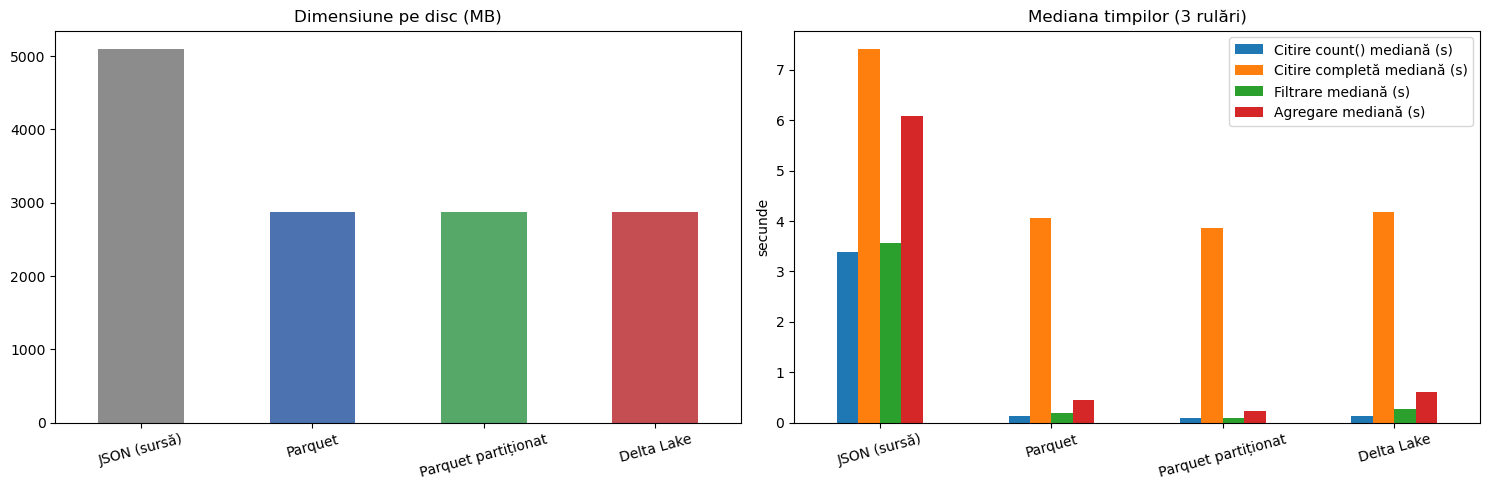

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
summary["Dimensiune (MB)"].plot.bar(ax=axes[0], color=["#8c8c8c", "#4c72b0", "#55a868", "#c44e52"])
axes[0].set_title("Dimensiune pe disc (MB)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

time_cols = [c for c in summary.columns if c.endswith("(s)")]
summary[time_cols].plot.bar(ax=axes[1])
axes[1].set_title(f"Mediana timpilor ({REPEATS} rulări)")
axes[1].set_ylabel("secunde")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [34]:
s = summary
def ratio(a, b, col):
    return s.loc[a, col] / max(s.loc[b, col], 1e-9)

print("Concluzii generate din valorile măsurate:")
print(f"- Spațiu: Parquet ocupă {s.loc['Parquet', 'Dimensiune (MB)']:,.1f} MB față de "
      f"{s.loc['JSON (sursă)', 'Dimensiune (MB)']:,.1f} MB pentru JSON ({s.loc['Parquet', 'vs sursă (%)']:+.1f}%).")
print(f"- Filtrare: Parquet e de {ratio('JSON (sursă)', 'Parquet', 'Filtrare mediană (s)'):.1f}x mai rapid decât JSON; "
      f"Parquet partiționat e de {ratio('Parquet', 'Parquet partiționat', 'Filtrare mediană (s)'):.1f}x mai rapid decât Parquet nepartiționat.")
print(f"- Agregare: JSON {s.loc['JSON (sursă)', 'Agregare mediană (s)']:.2f} s | Parquet {s.loc['Parquet', 'Agregare mediană (s)']:.2f} s | "
      f"Parquet part. {s.loc['Parquet partiționat', 'Agregare mediană (s)']:.2f} s | Delta {s.loc['Delta Lake', 'Agregare mediană (s)']:.2f} s")
print(f"- Delta vs Parquet partiționat (filtrare): {s.loc['Delta Lake', 'Filtrare mediană (s)']:.2f} s vs "
      f"{s.loc['Parquet partiționat', 'Filtrare mediană (s)']:.2f} s; dimensiune {s.loc['Delta Lake', 'Dimensiune (MB)']:,.1f} vs "
      f"{s.loc['Parquet partiționat', 'Dimensiune (MB)']:,.1f} MB (diferența = _delta_log + fișiere .crc).")
print(f"- Doar Delta Lake oferă istoric: {len(hist_pd)} versiuni (WRITE, APPEND, UPDATE, DELETE) și citirea v0 prin versionAsOf.")

Concluzii generate din valorile măsurate:
- Spațiu: Parquet ocupă 2,876.1 MB față de 5,094.4 MB pentru JSON (-43.5%).
- Filtrare: Parquet e de 17.8x mai rapid decât JSON; Parquet partiționat e de 2.0x mai rapid decât Parquet nepartiționat.
- Agregare: JSON 6.08 s | Parquet 0.44 s | Parquet part. 0.24 s | Delta 0.61 s
- Delta vs Parquet partiționat (filtrare): 0.26 s vs 0.10 s; dimensiune 2,870.2 vs 2,870.1 MB (diferența = _delta_log + fișiere .crc).
- Doar Delta Lake oferă istoric: 4 versiuni (WRITE, APPEND, UPDATE, DELETE) și citirea v0 prin versionAsOf.


### Interpretare (de completat/ajustat după rezultatele voastre)
- **JSON (sursă):** format text, pe rânduri; fiecare interogare parsează toate liniile → cel mai mare volum pe disc și cei mai mari timpi. Fără partiționare, fără istoric.
- **Parquet:** format coloană, comprimat (snappy) → spațiu mult redus; se citesc doar coloanele necesare (`ReadSchema`), filtrele sunt împinse în scanare (`PushedFilters`) și se folosesc statisticile min/max. `count()` este rezolvat din metadate.
- **Parquet partiționat:** aceeași compresie, dar filtrele pe `year` devin `PartitionFilters` → sunt citite doar directoarele relevante (partition pruning), vizibil în timpii de filtrare/agregare.
- **Delta Lake:** stochează datele tot ca Parquet (spațiu și performanță comparabile cu Parquet partiționat, plus `_delta_log` mic) și adaugă tranzacții ACID, `UPDATE`/`DELETE`, istoric și time travel. Costul: fișierele vechi rămân pe disc până la `VACUUM` (vezi dimensiunea după v3).
- **Observație metodologică:** timpii includ efectul cache-ului de pagini al sistemului de operare; mediana a 3 rulări reduce influența primei rulări „reci”.

In [ ]:
spark.stop()